In [1]:
#Environment and project paths
from pathlib import Path
import os, sys, random, json, time, copy, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.transforms import functional as TF

import os


In [7]:

from google.colab import drive
drive.mount('/content/drive')

%cd /content

# Remove the previous incomplete clone, if any
!rm -rf /content/repo

# Clone the specified branch
!git clone --branch vision-transformer --single-branch https://github.com/Teamoreteateo/CS3244-DeepWeeds.git /content/repo


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content
Cloning into '/content/repo'...
remote: Enumerating objects: 110, done.
remote: Counting objects: 100% (110/110), done.
remote: Compressing objects: 100% (81/81), done.
remote: Total 110 (delta 53), reused 59 (delta 22), pack-reused 0 (from 0)
Receiving objects: 100% (110/110), 7.70 MiB | 26.72 MiB/s, done.
Resolving deltas: 100% (53/53), done.


In [11]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU Name: NVIDIA L4


In [12]:

%cd /content/repo

!pip install -q scikit-image

!git log --oneline -2

# Copy your dataset from Google Drive
!mkdir -p data
!cp /content/drive/MyDrive/CS3244-DeepWeeds/data/labels.csv data/labels.csv
!rsync -ah --info=progress2 \
  /content/drive/MyDrive/CS3244-DeepWeeds/data/images/ \
  /content/repo/data/images/
# Verify that the files exist
!ls -l data/labels.csv
!ls data/images | wc -l




/content/repo
ec6daa7 (HEAD -> vision-transformer, origin/vision-transformer) Add files via upload
97ed393 Add resnet18 scratch result
        492.31M 100%    1.32MB/s    0:05:55 (xfr#17518, to-chk=0/17520)
-rw------- 1 root root 598898 Oct 21 20:12 data/labels.csv
17519


In [13]:

REPO_ROOT = Path.cwd().parent  # Current directory is notebooks
sys.path.insert(0, str(REPO_ROOT))


In [14]:


SEED = 42
VAL_FOLD = 0
SPLIT = "grouped"
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0
EPOCHS_SCRATCH = 15
EPOCHS_HF = 5
USE_WEIGHTED_SAMPLING = True
USE_CUTMIX = False
CUTMIX_PROBABILITY = 0.5
LEARNING_RATE_SCRATCH = 3e-4
LEARNING_RATE_HF = 2e-5
WEIGHT_DECAY = 1e-4

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "splits" / "folds.csv").exists() and (p / "data" / "images").is_dir():
            return p
    for p in candidates:
        if (p / "splits" / "folds.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not locate splits/folds.csv. Run this notebook from the project/repository "
        "or set PROJECT_ROOT manually."
    )

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
sys.path.insert(0, str(SRC_DIR))

# Reuse the project's shared data, transform, and metric implementations.
from src.data import load_folds
from src.data_pipeline import get_dataloaders, apply_cutmix
from src.metrics import evaluate as project_evaluate, log_result, summarise as project_summarise, SPECIES

IMG_DIR = PROJECT_ROOT / "data" / "images"
FOLDS_PATH = PROJECT_ROOT / "splits" / "folds.csv"
RESULTS_PATH = PROJECT_ROOT / "results.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "vit"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Image directory:", IMG_DIR, "| exists:", IMG_DIR.is_dir())
print("Fold manifest:", FOLDS_PATH, "| exists:", FOLDS_PATH.exists())
print("Device:", device)
print("PyTorch:", torch.__version__)
assert SPLIT == "grouped" and VAL_FOLD == 0, "Keep fold=0, split='grouped' for comparable runs."
assert IMG_DIR.is_dir(), f"Missing {IMG_DIR}. Download/unzip DeepWeeds images as instructed."
assert FOLDS_PATH.exists(), f"Missing {FOLDS_PATH}. Pull the committed split manifest first."

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything()


Project root: /content/repo
Image directory: /content/repo/data/images | exists: True
Fold manifest: /content/repo/splits/folds.csv | exists: True
Device: cuda
PyTorch: 2.11.0+cu130


## 2. Load the committed split and verify leakage


In [15]:
# Load the committed fold manifest through src/data.py; do not generate or replace folds.
df = load_folds()
required = {
    "Filename", "Label", "Species", "date", "instrument", "session",
    "is_test", "fold_random", "fold_grouped"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"folds.csv missing required columns: {sorted(missing)}")

if df["is_test"].dtype != bool:
    df["is_test"] = df["is_test"].astype(str).str.lower().map({"true": True, "false": False})
if df["is_test"].isna().any():
    raise ValueError("is_test contains missing/unparseable values")
if df["Filename"].duplicated().any():
    raise ValueError("folds.csv contains duplicate filenames")

non_test = df.loc[~df["is_test"]].copy()
fold_col = f"fold_{SPLIT}"
if non_test[fold_col].isna().any() or (non_test[fold_col] < 0).any():
    raise ValueError(f"Invalid fold assignments in {fold_col}")

# Use the project's DataLoader implementation and its train/evaluation transforms.
train_loader, val_loader, test_loader, classes = get_dataloaders(
    val_fold=VAL_FOLD,
    split=SPLIT,
    batch_size=BATCH_SIZE,
    augment=True,
    weighted_sampling=USE_WEIGHTED_SAMPLING,
    include_test=False,  # Held-out test is not used during training/model selection.
    num_workers=NUM_WORKERS,
    img_dir=IMG_DIR,
)
train_dataset = train_loader.dataset
val_dataset = val_loader.dataset
class_to_idx = {name: i for i, name in enumerate(classes)}
NUM_CLASSES = len(classes)

train_df = train_dataset.df.copy()
val_df = val_dataset.df.copy()
assert classes == SPECIES, f"Class order mismatch: {classes} vs {SPECIES}"
assert NUM_CLASSES == 9, f"Expected 9 DeepWeeds classes, found {NUM_CLASSES}"
assert len(train_df) and len(val_df)
assert set(train_df["Filename"]).isdisjoint(val_df["Filename"])
assert set(train_df["Filename"]).isdisjoint(set(df.loc[df["is_test"], "Filename"]))
assert set(val_df["Filename"]).isdisjoint(set(df.loc[df["is_test"], "Filename"]))
assert set(train_df["session"]).isdisjoint(val_df["session"]), "Grouped train/validation session leakage"
assert set(non_test["session"]).isdisjoint(set(df.loc[df["is_test"], "session"])), "Test session leakage"

print(f"Split: {SPLIT}; validation fold: {VAL_FOLD}")
print(f"Train: {len(train_df):,}; validation: {len(val_df):,}; held-out test excluded: {int(df['is_test'].sum()):,}")
print("Classes:", classes)
display(pd.DataFrame({
    "train": train_df["Species"].value_counts().reindex(classes, fill_value=0),
    "validation": val_df["Species"].value_counts().reindex(classes, fill_value=0),
}))

Split: grouped; validation fold: 0
Train: 10,820; validation: 2,454; held-out test excluded: 4,235
Classes: ['Chinee apple', 'Lantana', 'Parkinsonia', 'Parthenium', 'Prickly acacia', 'Rubber vine', 'Siam weed', 'Snake weed', 'Negative']


,train,validation
Species,,
Chinee apple,509,103
Lantana,681,184
Parkinsonia,809,222
Parthenium,648,177
Prickly acacia,581,87
Rubber vine,785,135
Siam weed,605,49
Snake weed,577,104
Negative,5625,1393


## 3. Image transforms and datasets

Training augmentation follows the  `02_splits_augmentation.ipynb` / `src/data_pipeline.py` Both models use ImageNet normalization so the pretrained model receives its expected input scale.

In [16]:
# get_dataloaders() above uses make_transforms() and DeepWeedsDataset from src/data_pipeline.py.
# Training augmentation and validation preprocessing are therefore shared with the other project methods.
# DeepWeedsDataset returns (image_tensor, integer_label, filename).
xb_batch = next(iter(train_loader))
xb, yb = xb_batch[0], xb_batch[1]
print("Image batch:", tuple(xb.shape), "| labels:", tuple(yb.shape))
assert xb.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

Image batch: (16, 3, 224, 224) | labels: (16,)


## 4. Metrics and training utilities

We report accuracy, macro-F1, macro precision/recall, weighted-F1, and validation loss.

In [17]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

# project_evaluate, log_result and project_summarise are imported from src/metrics.py above.
HAS_PROJECT_LOGGER = True

def evaluate_model(model, loader, criterion):
    model.eval()
    total_loss, total_n = 0.0, 0
    y_true, y_pred = [], []
    with torch.inference_mode():
        for batch in loader:
            images, labels = batch[0].to(device), batch[1].to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_n += n
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    # Keep the notebook's existing metrics and add the canonical project evaluation.
    project_metrics = project_evaluate(y_true, y_pred)
    return {
        "loss": total_loss / max(total_n, 1),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "project_macro_f1": project_metrics["macro_f1"],
        "project_weighted_f1": project_metrics["weighted_f1"],
        "weed_to_negative_rate": project_metrics["weed_to_negative_rate"],
        "project_per_class": project_metrics["per_class"],
        "project_cm": project_metrics["cm"],
        "project_cm_norm": project_metrics["cm_norm"],
        "y_true": y_true,
        "y_pred": y_pred,
    }

def train_model(model, train_loader, val_loader, epochs, lr, weight_decay, run_name,
                use_cutmix=False, cutmix_probability=0.5):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    history = []
    best_f1 = -1.0
    best_state = None
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, seen, correct = 0.0, 0, 0
        for batch in train_loader:
            images, labels = batch[0].to(device), batch[1].to(device)
            if use_cutmix:
                images, mixed_labels = apply_cutmix(
                    images, labels, NUM_CLASSES, probability=cutmix_probability, alpha=1.0
                )
                logits = model(images)
                if mixed_labels.ndim == 2:
                    loss = -(mixed_labels * torch.log_softmax(logits, dim=1)).sum(dim=1).mean()
                else:
                    loss = criterion(logits, mixed_labels)
            else:
                logits = model(images)
                loss = criterion(logits, labels)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            n = labels.size(0)
            running_loss += loss.item() * n
            seen += n
            correct += (logits.argmax(dim=1) == labels).sum().item()
        scheduler.step()
        val_metrics = evaluate_model(model, val_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": running_loss / max(seen, 1),
            "train_accuracy": correct / max(seen, 1),
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "val_macro_precision": val_metrics["macro_precision"],
            "val_macro_recall": val_metrics["macro_recall"],
            "val_weighted_f1": val_metrics["weighted_f1"],
            "lr": optimizer.param_groups[0]["lr"],
        }
        history.append(row)
        print(f"{run_name} | epoch {epoch:02d}/{epochs} | "
              f"train loss {row['train_loss']:.4f} acc {row['train_accuracy']:.4f} | "
              f"val loss {row['val_loss']:.4f} acc {row['val_accuracy']:.4f} "
              f"macro-F1 {row['val_macro_f1']:.4f} weighted-F1 {row['val_weighted_f1']:.4f}")
        if row["val_macro_f1"] > best_f1:
            best_f1 = row["val_macro_f1"]
            best_state = copy.deepcopy(model.state_dict())
            torch.save({
                "model_state_dict": best_state,
                "run_name": run_name,
                "best_epoch": epoch,
                "best_val_macro_f1": best_f1,
                "classes": classes,
                "split": SPLIT,
                "val_fold": VAL_FOLD,
                "seed": SEED,
            }, OUTPUT_DIR / f"{run_name}_best.pt")
        scheduler.step if False else None

    if best_state is not None:
        model.load_state_dict(best_state)
    best_metrics = evaluate_model(model, val_loader, criterion)
    history_df = pd.DataFrame(history)
    history_df.to_csv(OUTPUT_DIR / f"{run_name}_history.csv", index=False)
    result_summary = {
        k: v for k, v in best_metrics.items()
        if k in ("loss", "accuracy", "macro_f1", "macro_precision", "macro_recall",
                 "weighted_f1", "project_macro_f1", "project_weighted_f1", "weed_to_negative_rate")
    }
    result_summary["best_val_macro_f1"] = best_f1
    result_summary["best_epoch"] = int(history_df.loc[history_df["val_macro_f1"].idxmax(), "epoch"])
    result_summary["n_train"] = len(train_dataset)
    result_summary["n_validation"] = len(val_dataset)
    result_summary["split"] = SPLIT
    result_summary["val_fold"] = VAL_FOLD
    result_summary["seed"] = SEED
    if HAS_PROJECT_LOGGER:
        try:
            # Project convention: log_result(model_name, split_scheme, params, summary)
            project_metrics = project_evaluate(best_metrics["y_true"], best_metrics["y_pred"])
            log_summary = project_summarise([project_metrics])
            log_result(run_name, SPLIT, {
                "val_fold": VAL_FOLD, "seed": SEED, "epochs": epochs,
                "batch_size": BATCH_SIZE, "lr": lr, "weight_decay": weight_decay,
                "weighted_sampling": USE_WEIGHTED_SAMPLING, "cutmix": use_cutmix,
            }, log_summary)
            print("Logged through metrics.log_result to project results.csv.")
        except Exception as exc:
            print("Project log_result call failed; see note below:", repr(exc))
            print("Metrics are saved in:", OUTPUT_DIR)
    else:
        print("Project logger unavailable; metrics are saved in outputs/vit, not appended to results.csv.")
    return model, history_df, result_summary


## 5. Model A — Vision Transformer trained from scratch

This is a small ViT built from scratch specifically for this dataset: 16×16 patches (196 patches at 224×224), learned class token and positional embeddings, 6 Transformer encoder layers, 8 attention heads, and a 9-class output head. No pretrained weights are loaded.

In [18]:
class ScratchViT(nn.Module):
    def __init__(self, num_classes, image_size=224, patch_size=16, embed_dim=384,
                 depth=6, num_heads=6, mlp_ratio=4.0, dropout=0.1):
        super().__init__()
        assert image_size % patch_size == 0
        self.patch_size = patch_size
        n_patches = (image_size // patch_size) ** 2
        self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.zeros(1, n_patches + 1, embed_dim))
        self.pos_drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=num_heads, dim_feedforward=int(embed_dim * mlp_ratio),
            dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))
        self.head = nn.Sequential(nn.LayerNorm(embed_dim), nn.Dropout(dropout),
                                  nn.Linear(embed_dim, num_classes))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.kaiming_normal_(self.patch_embed.weight, mode="fan_out", nonlinearity="relu")
        if self.patch_embed.bias is not None:
            nn.init.zeros_(self.patch_embed.bias)
    def forward(self, x):
        x = self.patch_embed(x)                 # B, D, H/patch, W/patch
        x = x.flatten(2).transpose(1, 2)        # B, N, D
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls, x), dim=1) + self.pos_embed
        x = self.pos_drop(x)
        x = self.encoder(x)
        return self.head(x[:, 0])

scratch_model = ScratchViT(NUM_CLASSES, image_size=IMAGE_SIZE, patch_size=16,
                           embed_dim=384, depth=6, num_heads=6, dropout=0.1)
print(scratch_model)
print(f"Trainable parameters: {sum(p.numel() for p in scratch_model.parameters() if p.requires_grad):,}")


ScratchViT(
  (patch_embed): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
  (pos_drop): Dropout(p=0.1, inplace=False)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=384, out_features=384, bias=True)
        )
        (linear1): Linear(in_features=384, out_features=1536, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=1536, out_features=384, bias=True)
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
    (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
  )
  (head): Sequential(
    (0): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
    (1): Dropou

/tmp/ipykernel_10517/2938882161.py:16: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(layer, num_layers=depth, norm=nn.LayerNorm(embed_dim))


In [19]:
scratch_model, scratch_history, scratch_summary = train_model(
    scratch_model, train_loader, val_loader,
    epochs=EPOCHS_SCRATCH,
    lr=LEARNING_RATE_SCRATCH,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_scratch",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(scratch_history.tail())
print("Best validation summary:", scratch_summary)


vit_scratch | epoch 01/15 | train loss 2.1802 acc 0.1655 | val loss 1.8958 acc 0.3700 macro-F1 0.1685 weighted-F1 0.3779
vit_scratch | epoch 02/15 | train loss 1.8722 acc 0.3030 | val loss 1.5600 acc 0.3749 macro-F1 0.2204 weighted-F1 0.4033
vit_scratch | epoch 03/15 | train loss 1.5926 acc 0.4043 | val loss 1.8770 acc 0.3317 macro-F1 0.2959 weighted-F1 0.3413
vit_scratch | epoch 04/15 | train loss 1.4661 acc 0.4646 | val loss 1.9265 acc 0.2922 macro-F1 0.2737 weighted-F1 0.2923
vit_scratch | epoch 05/15 | train loss 1.3583 acc 0.5035 | val loss 1.7969 acc 0.3394 macro-F1 0.3033 weighted-F1 0.3623
vit_scratch | epoch 06/15 | train loss 1.2895 acc 0.5250 | val loss 1.6570 acc 0.3875 macro-F1 0.3236 weighted-F1 0.4148
vit_scratch | epoch 07/15 | train loss 1.2127 acc 0.5571 | val loss 1.6839 acc 0.3684 macro-F1 0.3120 weighted-F1 0.3648
vit_scratch | epoch 08/15 | train loss 1.1489 acc 0.5798 | val loss 1.8996 acc 0.3423 macro-F1 0.3241 weighted-F1 0.3401
vit_scratch | epoch 09/15 | trai

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
10,11,0.932649,0.661275,1.657205,0.411573,0.382197,0.357184,0.518999,0.407522,0.000050
11,12,0.841117,0.698244,1.577832,0.443765,0.382512,0.353640,0.505316,0.454954,0.000029
12,13,0.811045,0.711922,1.700453,0.420130,0.379970,0.350550,0.521777,0.430379,0.000013
13,14,0.793718,0.715619,1.582848,0.447840,0.397660,0.366593,0.533636,0.459816,0.000003
14,15,0.771000,0.731793,1.599862,0.446210,0.402466,0.370898,0.540843,0.457088,0.000000


Best validation summary: {'loss': 1.5998616075263143, 'accuracy': 0.44621026894865523, 'macro_f1': 0.40246627258812423, 'macro_precision': 0.3708978881069362, 'macro_recall': 0.5408425063678567, 'weighted_f1': 0.45708845835145556, 'project_macro_f1': 0.40246627258812423, 'project_weighted_f1': 0.45708845835145556, 'weed_to_negative_rate': np.float64(0.0885956644674835), 'best_val_macro_f1': 0.40246627258812423, 'best_epoch': 15, 'n_train': 10820, 'n_validation': 2454, 'split': 'grouped', 'val_fold': 0, 'seed': 42}


## 6. Model B — Hugging Face pretrained ViT-B/16 fine-tuned on DeepWeeds

Uses Hugging Face checkpoint `google/vit-base-patch16-224-in21k`. The pretrained backbone is initialized from the public checkpoint, and the classifier is replaced with a 9-class head. This is **fine-tuning**, not frozen embeddings: all backbone parameters are trainable. Internet access is needed the first time unless the checkpoint is already cached.

In [20]:
# Install once if needed in the notebook environment:
# %pip install -U transformers safetensors

try:
    from transformers import ViTForImageClassification
except ImportError as exc:
    raise ImportError("Install Hugging Face Transformers first: %pip install -U transformers safetensors") from exc

HF_CHECKPOINT = "google/vit-base-patch16-224-in21k"
id2label = {i: name for i, name in enumerate(classes)}
label2id = {name: i for i, name in enumerate(classes)}

hf_model = ViTForImageClassification.from_pretrained(
    HF_CHECKPOINT,
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)
# Verify all parameters are trainable for a full fine-tuning comparison.
for parameter in hf_model.parameters():
    parameter.requires_grad = True

class HFViTClassifier(nn.Module):
    def __init__(self, hf_model):
        super().__init__()
        self.hf_model = hf_model
    def forward(self, pixel_values):
        return self.hf_model(pixel_values=pixel_values).logits

hf_classifier = HFViTClassifier(hf_model)
print("Checkpoint:", HF_CHECKPOINT)
print("Trainable parameters:", f"{sum(p.numel() for p in hf_classifier.parameters() if p.requires_grad):,}")


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.weight | UNEXPECTED | 
pooler.dense.bias   | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Checkpoint: google/vit-base-patch16-224-in21k
Trainable parameters: 85,805,577


In [21]:
hf_classifier, hf_history, hf_summary = train_model(
    hf_classifier, train_loader, val_loader,
    epochs=EPOCHS_HF,
    lr=LEARNING_RATE_HF,
    weight_decay=WEIGHT_DECAY,
    run_name="vit_hf_vit_base_patch16_224_in21k_finetuned",
    use_cutmix=USE_CUTMIX,
    cutmix_probability=CUTMIX_PROBABILITY,
)
display(hf_history.tail())
print("Best validation summary:", hf_summary)


vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 01/5 | train loss 0.9806 acc 0.7742 | val loss 1.1731 acc 0.5978 macro-F1 0.6108 weighted-F1 0.6068
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 02/5 | train loss 0.3388 acc 0.9236 | val loss 0.9935 acc 0.6895 macro-F1 0.6647 weighted-F1 0.7050
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 03/5 | train loss 0.1930 acc 0.9585 | val loss 0.7034 acc 0.7885 macro-F1 0.7398 weighted-F1 0.8081
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 04/5 | train loss 0.1488 acc 0.9669 | val loss 0.6775 acc 0.8020 macro-F1 0.7439 weighted-F1 0.8178
vit_hf_vit_base_patch16_224_in21k_finetuned | epoch 05/5 | train loss 0.1113 acc 0.9773 | val loss 0.7209 acc 0.7922 macro-F1 0.7306 weighted-F1 0.8113
Logged through metrics.log_result to project results.csv.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_f1,val_macro_precision,val_macro_recall,val_weighted_f1,lr
0,1,0.980564,0.774214,1.173106,0.597800,0.610816,0.576834,0.810847,0.606789,0.000018
1,2,0.338825,0.923567,0.993522,0.689487,0.664723,0.623157,0.822206,0.705020,0.000013
2,3,0.192960,0.958503,0.703353,0.788509,0.739760,0.714289,0.842558,0.808097,0.000007
3,4,0.148752,0.966913,0.677482,0.801956,0.743934,0.715842,0.849321,0.817783,0.000002
4,5,0.111300,0.977264,0.720930,0.792176,0.730604,0.714011,0.845665,0.811293,0.000000


Best validation summary: {'loss': 0.6774819624453127, 'accuracy': 0.8019559902200489, 'macro_f1': 0.7439336114133162, 'macro_precision': 0.7158424662814089, 'macro_recall': 0.8493208605625107, 'weighted_f1': 0.8177827824536109, 'project_macro_f1': 0.7439336114133162, 'project_weighted_f1': 0.8177827824536109, 'weed_to_negative_rate': np.float64(0.057492931196983975), 'best_val_macro_f1': 0.7439336114133162, 'best_epoch': 4, 'n_train': 10820, 'n_validation': 2454, 'split': 'grouped', 'val_fold': 0, 'seed': 42}


## 7. Compare validation results

These are validation results only; use them for model selection and error analysis, not as a final unbiased test estimate. The `is_test=True` set remains untouched.

,loss,accuracy,macro_f1,macro_precision,macro_recall,weighted_f1,best_epoch
model,,,,,,,
Hugging Face ViT-B/16 fine-tuned,0.677482,0.801956,0.743934,0.715842,0.849321,0.817783,4
ViT from scratch,1.599862,0.446210,0.402466,0.370898,0.540843,0.457088,15


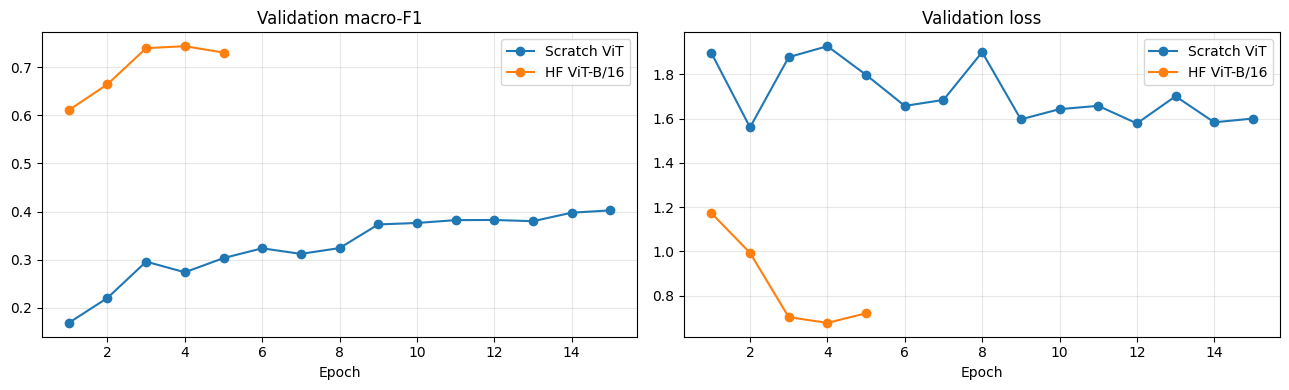

Saved outputs to: /content/repo/outputs/vit


In [22]:
comparison = pd.DataFrame([
    {"model": "ViT from scratch", **{k: v for k, v in scratch_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
    {"model": "Hugging Face ViT-B/16 fine-tuned", **{k: v for k, v in hf_summary.items()
                                    if k in ["loss", "accuracy", "macro_f1", "macro_precision",
                                             "macro_recall", "weighted_f1", "best_epoch"]}},
]).set_index("model")
display(comparison.sort_values("macro_f1", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for hist, name in [(scratch_history, "Scratch ViT"), (hf_history, "HF ViT-B/16")]:
    axes[0].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label=name)
    axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", label=name)
axes[0].set_title("Validation macro-F1")
axes[1].set_title("Validation loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

comparison.to_csv(OUTPUT_DIR / "validation_comparison.csv")
print("Saved outputs to:", OUTPUT_DIR)


## 8. Validation error analysis

Per-class report and confusion matrices are generated on the validation fold only. Inspect these alongside macro-F1 because a high overall accuracy can hide poor performance on less frequent weed species.

\n========================================================================
Scratch ViT
                precision    recall  f1-score   support

  Chinee apple     0.2329    0.3301    0.2731       103
       Lantana     0.5000    0.7446    0.5983       184
   Parkinsonia     0.4017    0.8378    0.5431       222
    Parthenium     0.2727    0.2542    0.2632       177
Prickly acacia     0.3976    0.7586    0.5217        87
   Rubber vine     0.3810    0.6519    0.4809       135
     Siam weed     0.1106    0.5306    0.1831        49
    Snake weed     0.2085    0.4231    0.2794       104
      Negative     0.8330    0.3367    0.4796      1393

      accuracy                         0.4462      2454
     macro avg     0.3709    0.5408    0.4025      2454
  weighted avg     0.6222    0.4462    0.4571      2454



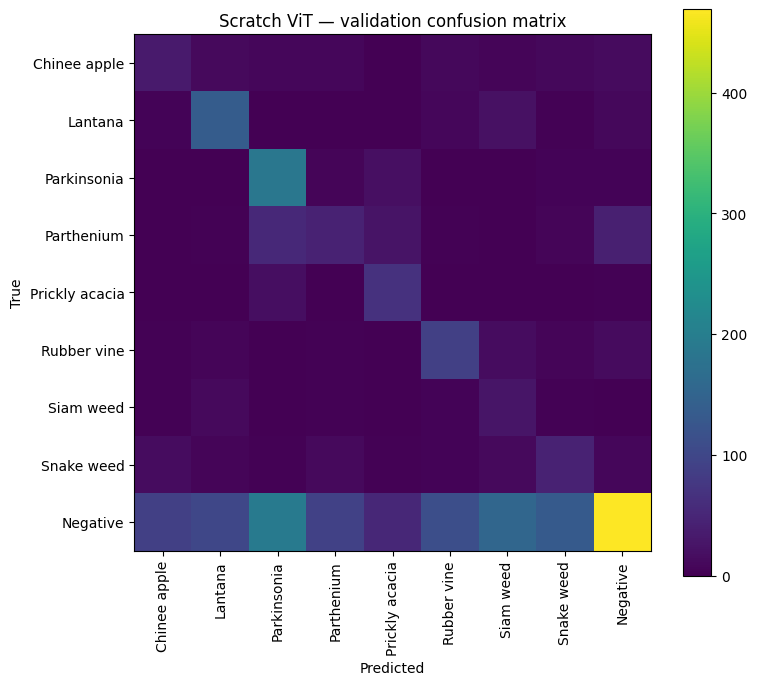

\n========================================================================
HF ViT-B/16
                precision    recall  f1-score   support

  Chinee apple     0.4500    0.7864    0.5724       103
       Lantana     0.9653    0.9076    0.9356       184
   Parkinsonia     0.7778    0.9775    0.8663       222
    Parthenium     0.8836    0.7288    0.7988       177
Prickly acacia     0.4775    0.9770    0.6415        87
   Rubber vine     0.9298    0.7852    0.8514       135
     Siam weed     0.3121    1.0000    0.4757        49
    Snake weed     0.7009    0.7212    0.7109       104
      Negative     0.9455    0.7602    0.8428      1393

      accuracy                         0.8020      2454
     macro avg     0.7158    0.8493    0.7439      2454
  weighted avg     0.8661    0.8020    0.8178      2454



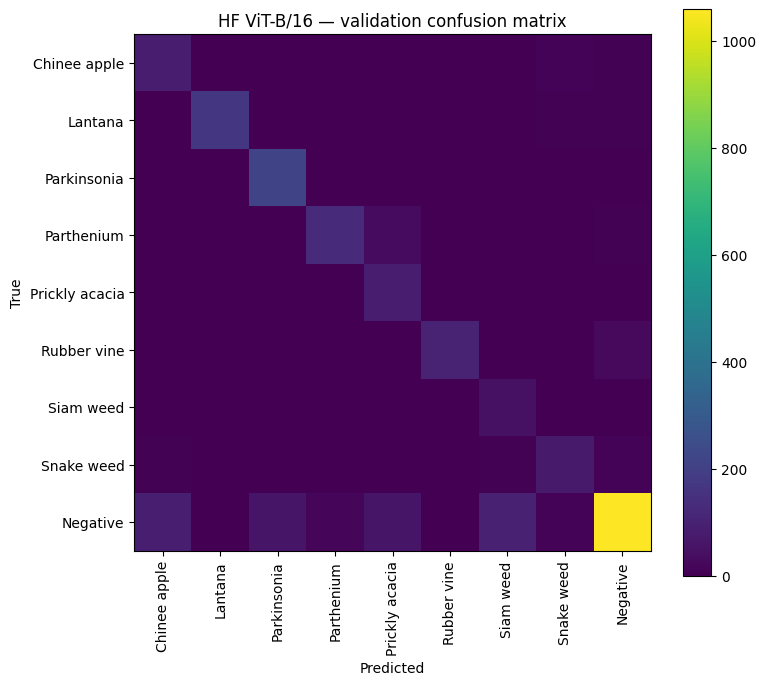

In [23]:
criterion = nn.CrossEntropyLoss()
scratch_eval = evaluate_model(scratch_model, val_loader, criterion)
hf_eval = evaluate_model(hf_classifier, val_loader, criterion)

for name, result in [("Scratch ViT", scratch_eval), ("HF ViT-B/16", hf_eval)]:
    print("\\n" + "=" * 72)
    print(name)
    print(classification_report(result["y_true"], result["y_pred"],
                                labels=list(range(NUM_CLASSES)), target_names=classes,
                                digits=4, zero_division=0))
    cm = confusion_matrix(result["y_true"], result["y_pred"], labels=list(range(NUM_CLASSES)))
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{name} — validation confusion matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_xticks(range(NUM_CLASSES), classes, rotation=90)
    ax.set_yticks(range(NUM_CLASSES), classes)
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()
